In [1]:
from datasets import load_dataset
import pandas as pd
from pathlib import Path

out_dir = Path("../data/rut")
out_dir.mkdir(parents=True, exist_ok=True)

# Load the Hugging Face dataset
ds = load_dataset("hafiz-hassaan-saeed/Roman-Urdu-Toxic-Corpus", split="train")

# Convert to pandas and keep consistent columns
df = ds.to_pandas()                    # columns are likely: "Roman_Urdu", "Toxic"
df = df.rename(columns={"Roman_Urdu": "text", "Toxic": "label"})
df["label"] = df["label"].astype(int)  # ensure 0/1 integers
df["source"] = "rut"
df["script"] = "roman"

# Save parquet + csv for convenience
df.to_parquet(out_dir / "rut.parquet", index=False)
df.to_csv(out_dir / "rut.csv", index=False)

print(df.shape, df.head())


C:\Users\HP\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\HP\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\datasets--hafiz-hassaan-saeed--Roman-Urdu-Toxic-Corpus. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administr

(72771, 4)                                                 text  label source script
0  Jo ata hy nea treqa batata hy kia lul mara how...      1    rut  roman
1  Lakh lanat ho terie shakal par... Aik chez dik...      1    rut  roman
2              Bakwaas bevqoof bna rahay ho logon ko      1    rut  roman
3                                 O lanti das bhi de      1    rut  roman
4                      lun b gold ka hona chahiy tha      1    rut  roman


label
0    0.820024
1    0.179976
Name: proportion, dtype: float64


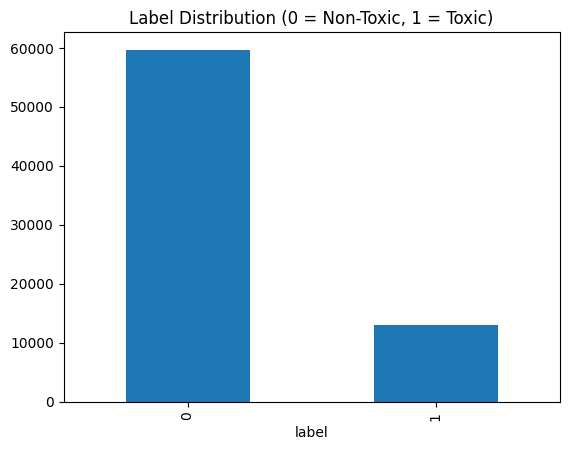

In [2]:
df["label"].value_counts().plot(kind="bar", title="Label Distribution (0 = Non-Toxic, 1 = Toxic)")
print(df["label"].value_counts(normalize=True))


              precision    recall  f1-score   support

           0      0.974     0.950     0.962     11935
           1      0.794     0.885     0.837      2620

    accuracy                          0.938     14555
   macro avg      0.884     0.917     0.899     14555
weighted avg      0.942     0.938     0.939     14555



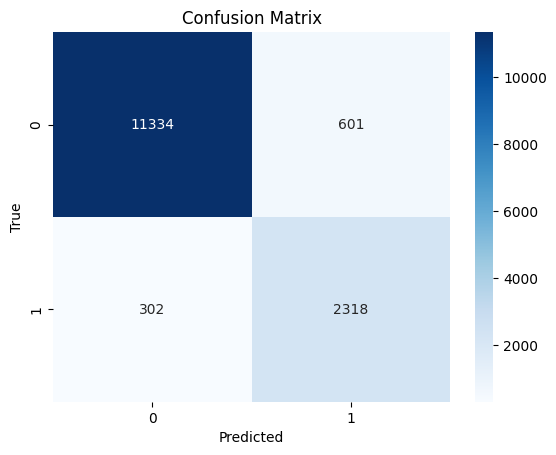

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)

vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(3,5), min_df=3, max_features=200000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = LogisticRegression(max_iter=2000, class_weight="balanced", n_jobs=-1)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [4]:
import joblib, pathlib
pathlib.Path("../models").mkdir(parents=True, exist_ok=True)
joblib.dump(model, "../models/rut_baseline_tfidf.joblib")
joblib.dump(vectorizer, "../models/rut_vectorizer.joblib")


['../models/rut_vectorizer.joblib']

💡 **Explanation — How We Solved the Class Imbalance Problem**

Your dataset is very imbalanced:

- **Non-toxic (0)** → ~82%  
- **Toxic (1)** → ~18%

If we hadn’t done anything, the model could simply predict “0” for most examples and still get 82% accuracy — but that would fail to detect toxic comments effectively.

---

### 🧮 1. Stratified Splitting

When we divided the data into training and testing sets:

```python
train_test_split(..., stratify=df["label"])
This ensured both splits had the same proportion of toxic and non-toxic examples — avoiding a biased test set.

⚖️ 2. Balanced Class Weights
We trained the model with:

class_weight="balanced"
This tells Logistic Regression to automatically up-weight the minority class (1) and down-weight the majority class (0) during training.

Mathematically, it assigns each class a weight inversely proportional to its frequency:

 
So, in our case:

Toxic samples get ~4.5× more weight

Non-toxic samples get ~0.5× weight

That way, the model’s loss function penalizes missing a toxic comment much more than misclassifying a clean one, making it learn both classes fairly.

📈 3. Macro-Averaged Evaluation Metrics
We used:

classification_report(..., digits=3)
and looked at macro F1, precision, and recall, which treat both classes equally — not biased by class size.

🧾 Your macro F1 = 0.899, which shows the model is learning both classes well.

✅ Result
Without balancing, your model would’ve probably achieved:

Accuracy ≈ 0.83–0.85

F1 (toxic class) ≈ 0.6–0.7

With balancing, it jumped to:

Accuracy = 0.938

F1 (toxic) = 0.837






In [5]:
with open("../data/ruhsold/hate_words_roman_urdu.txt", encoding="utf-8") as f:
    words = [w.strip() for w in f if w.strip() and not w.startswith("_")]
print("Total hate words:", len(words))
print(words[:15])


Total hate words: 724
['ahmaq', 'manjan', 'panchaiyet', 'gandu', 'gandu', 'gaanddu', 'ganduboy', 'gaandduboy', 'ganduguy', 'gaandduguy', 'gandun', 'ganduo', 'gaanddooon', 'ganduon', 'gaanddooon']


In [13]:
import pandas as pd, csv
from pathlib import Path

base = Path("../data/ruhsold")

FILES = ["task_1_train.tsv", "task_1_validation.tsv", "task_1_test.tsv"]  # change to *.tsv.txt if needed

def read_any(path):
    # Read with no header, tolerant of quotes/emojis/irregular rows
    return pd.read_csv(
        base / path,
        sep="\t",
        header=None,
        engine="python",
        encoding="utf-8",
        quoting=csv.QUOTE_NONE,
        on_bad_lines="skip",
        dtype=str
    )

dfs = [read_any(f) for f in FILES]
raw = pd.concat(dfs, ignore_index=True)
print("Raw shape:", raw.shape)

# Drop fully empty rows
raw = raw.dropna(how="all")
raw = raw.fillna("")

# ---- Auto-detect label & text columns ----
# Candidate label tokens (case-insensitive)
label_tokens = {"hate","offensive","abusive","clean","neutral","none","not","other","toxic","0","1"}

def is_label_series(s):
    vals = set(v.strip().lower() for v in s.astype(str).unique() if str(v).strip() != "")
    # Consider it a label column if small number of unique values and mostly in our set
    return (0 < len(vals) <= 10) and (len(vals - label_tokens) <= 2)

label_col = None
text_col = None

# 1) Try to find a label-like column
for c in raw.columns:
    if is_label_series(raw[c]):
        label_col = c
        break

# 2) Pick text as the *longest average length* column that's not the label
avg_len = {c: raw[c].astype(str).str.len().mean() for c in raw.columns if c != label_col}
text_col = max(avg_len, key=avg_len.get)

print("Detected columns -> text:", text_col, "| label:", label_col)

# Build cleaned dataframe
df_ruhsold = raw[[text_col, label_col]].copy()
df_ruhsold.columns = ["text", "raw_label"]
df_ruhsold["text"] = df_ruhsold["text"].astype(str).str.strip()
df_ruhsold["raw_label"] = df_ruhsold["raw_label"].astype(str).str.strip().str.lower()

# Map to {0,1}
label_map = {
    "hate": 1, "offensive": 1, "abusive": 1, "toxic": 1, "1": 1,
    "clean": 0, "neutral": 0, "none": 0, "not": 0, "other": 0, "0": 0
}
df_ruhsold["label"] = df_ruhsold["raw_label"].map(label_map)

# Keep only rows with valid labels and non-empty text
df_ruhsold = df_ruhsold.dropna(subset=["label"]).copy()
df_ruhsold = df_ruhsold[df_ruhsold["text"].str.strip() != ""]
df_ruhsold["label"] = df_ruhsold["label"].astype(int)

# Add metadata and final schema
df_ruhsold["source"] = "ruhsold"
df_ruhsold["script"] = "roman"
df_ruhsold = df_ruhsold[["text", "label", "source", "script"]]

print("Clean shape:", df_ruhsold.shape)
print(df_ruhsold["label"].value_counts(normalize=True))
df_ruhsold.head(8)


Raw shape: (10013, 2)
Detected columns -> text: 0 | label: 1
Clean shape: (10013, 4)
label
1    0.534206
0    0.465794
Name: proportion, dtype: float64


,text,label,source,script
0,pichwara se akhrot kahe fod rahe ho chicha,1,ruhsold,roman
1,bhaunk bhaunk ke pagal ho jaata ab tak....,0,ruhsold,roman
2,shivsaina nam mulla saina rakh hijra uddh...,0,ruhsold,roman
3,there are some yahodi daboo like imran chore z...,0,ruhsold,roman
4,"chutiye ye hunduism ni he islam he , isme koi ...",0,ruhsold,roman
5,han g rakhail e awal kiya bak rai hai. kisay a...,0,ruhsold,roman
6,can you please stop pinning a fan everytime br...,0,ruhsold,roman
7,hum kisi se km nhi,1,ruhsold,roman


In [14]:
df_ruhsold.to_csv(base / "ruhsold.csv", index=False)


In [15]:
pd.read_csv(base / "ruhsold.csv").shape


(10013, 4)

In [22]:
import pandas as pd
from pathlib import Path

# install once (if needed)
# !pip install openpyxl

base = Path("../data/urdu_youtube")
xlsx = base / "Urdu Abusive Dataset" / "Urdu Abusive Dataset.xlsx"  # use .csv here if you didn't rename

# Read the Excel file
df_raw = pd.read_excel(xlsx, engine="openpyxl")
print(df_raw.shape)
print(df_raw.columns.tolist())
print(df_raw.head(3))


(2171, 2)
['comment_class', 'comment_text']
   comment_class                                       comment_text
0           True                             کہ کے لے لی شام دلے کی
1           True  اب اگر اس نے کچھ جواب دیا تو اس کی گانڈ مار دی...
2           True  اب ان چوتیوں نے وہ جو کنسرٹ ہو رہا تھا وہ بھی ...


In [23]:
df_urdu = df_raw.rename(columns={
    "comment_text": "text",
    "comment_class": "raw_label"
})

# Map TRUE/FALSE → 1/0 robustly
df_urdu["label"] = (
    df_urdu["raw_label"]
      .astype(str).str.strip().str.lower()
      .map({"true": 1, "false": 0, "1": 1, "0": 0})
      .astype(int)
)

df_urdu["source"] = "urdu_youtube"
df_urdu["script"] = "urdu"
df_urdu = df_urdu[["text", "label", "source", "script"]]

# Drop empties and save
df_urdu = df_urdu.dropna(subset=["text"])
df_urdu = df_urdu[df_urdu["text"].astype(str).str.strip() != ""]
out_path = base / "urdu_youtube.csv"
df_urdu.to_csv(out_path, index=False)

print("Final shape:", df_urdu.shape, "→ saved to", out_path)
print(df_urdu["label"].value_counts(normalize=True))
df_urdu.head()


Final shape: (2170, 4) → saved to ..\data\urdu_youtube\urdu_youtube.csv
label
1    0.510599
0    0.489401
Name: proportion, dtype: float64


,text,label,source,script
0,کہ کے لے لی شام دلے کی,1,urdu_youtube,urdu
1,اب اگر اس نے کچھ جواب دیا تو اس کی گانڈ مار دی...,1,urdu_youtube,urdu
2,اب ان چوتیوں نے وہ جو کنسرٹ ہو رہا تھا وہ بھی ...,1,urdu_youtube,urdu
3,اب ان کی گانڈ میں ہاتھ ڈال کر انتڑیاں نکالے گا...,1,urdu_youtube,urdu
4,اب تک سکی سب سے اچھی ویڈیو ہے,0,urdu_youtube,urdu


In [25]:
import pandas as pd, pathlib

root = pathlib.Path("..")
rut  = pd.read_csv(root / "data/rut/rut.csv")
ruhs = pd.read_csv(root / "data/ruhsold/ruhsold.csv")
urdu = pd.read_csv(root / "data/urdu_youtube/urdu_youtube.csv")

df_all = pd.concat([rut, ruhs, urdu], ignore_index=True).dropna(subset=["text","label"])
df_all["label"] = df_all["label"].astype(int)
df_all.to_csv(root / "data/all_combined.csv", index=False)

print(df_all.shape)
print(df_all["source"].value_counts())
print(df_all["script"].value_counts())
print(df_all["label"].value_counts(normalize=True))
df_all.head()


(84954, 4)
source
rut             72771
ruhsold         10013
urdu_youtube     2170
Name: count, dtype: int64
script
roman    82784
urdu      2170
Name: count, dtype: int64
label
0    0.769828
1    0.230172
Name: proportion, dtype: float64


,text,label,source,script
0,Jo ata hy nea treqa batata hy kia lul mara how...,1,rut,roman
1,Lakh lanat ho terie shakal par... Aik chez dik...,1,rut,roman
2,Bakwaas bevqoof bna rahay ho logon ko,1,rut,roman
3,O lanti das bhi de,1,rut,roman
4,lun b gold ka hona chahiy tha,1,rut,roman


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import joblib, pathlib

X_train, X_test, y_train, y_test = train_test_split(
    df_all["text"], df_all["label"],
    test_size=0.2, random_state=42, stratify=df_all["label"]
)

vec = TfidfVectorizer(analyzer="char", ngram_range=(3,5), min_df=3, max_features=300_000)
Xtr = vec.fit_transform(X_train); Xte = vec.transform(X_test)

clf = LogisticRegression(max_iter=2000, class_weight="balanced", n_jobs=-1)
clf.fit(Xtr, y_train)
pred = clf.predict(Xte)

print(classification_report(y_test, pred, digits=3))

# save
pathlib.Path("../models").mkdir(exist_ok=True)
joblib.dump(vec, "../models/combined_vectorizer.joblib")
joblib.dump(clf, "../models/combined_baseline.joblib")


              precision    recall  f1-score   support

           0      0.940     0.853     0.894     13080
           1      0.624     0.817     0.708      3911

    accuracy                          0.845     16991
   macro avg      0.782     0.835     0.801     16991
weighted avg      0.867     0.845     0.851     16991



['../models/combined_baseline.joblib']

In [27]:
import numpy as np
from sklearn.metrics import f1_score, precision_recall_fscore_support

test_df = df_all.iloc[y_test.index] if hasattr(y_test, "index") else df_all.loc[X_test.index]
test_df = test_df.copy()
test_df["pred"] = pred

def by(group_col):
    rows = []
    for k, g in test_df.groupby(group_col):
        p, r, f1, _ = precision_recall_fscore_support(g["label"], g["pred"], average="binary", zero_division=0)
        rows.append((k, len(g), p, r, f1))
    return pd.DataFrame(rows, columns=[group_col, "n", "precision_1", "recall_1", "f1_1"]).sort_values("n", ascending=False)

print("\nBy script:")
display(by("script"))
print("\nBy source:")
display(by("source"))



By script:


,script,n,precision_1,recall_1,f1_1
0,roman,16554,0.611808,0.806837,0.695917
1,urdu,437,0.853846,0.986667,0.915464



By source:


,source,n,precision_1,recall_1,f1_1
1,rut,14505,0.640793,0.873696,0.739336
0,ruhsold,2049,0.534936,0.649043,0.586491
2,urdu_youtube,437,0.853846,0.986667,0.915464


# EDA Visualization

In [28]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns

sns.set(style="whitegrid", palette="viridis")

df = pd.read_csv("../data/all_combined.csv")
print(df.shape)
df.head()


(84954, 4)


,text,label,source,script
0,Jo ata hy nea treqa batata hy kia lul mara how...,1,rut,roman
1,Lakh lanat ho terie shakal par... Aik chez dik...,1,rut,roman
2,Bakwaas bevqoof bna rahay ho logon ko,1,rut,roman
3,O lanti das bhi de,1,rut,roman
4,lun b gold ka hona chahiy tha,1,rut,roman


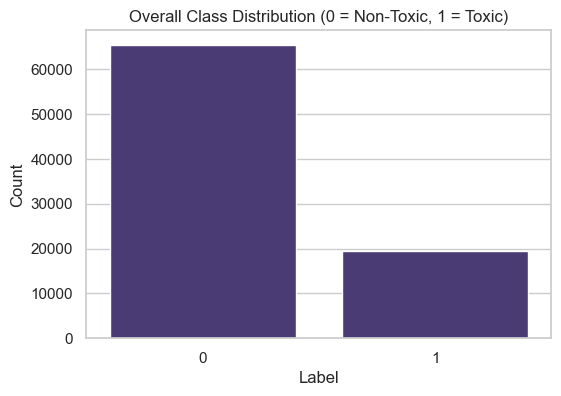

In [29]:
plt.figure(figsize=(6,4))
sns.countplot(x="label", data=df)
plt.title("Overall Class Distribution (0 = Non-Toxic, 1 = Toxic)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()


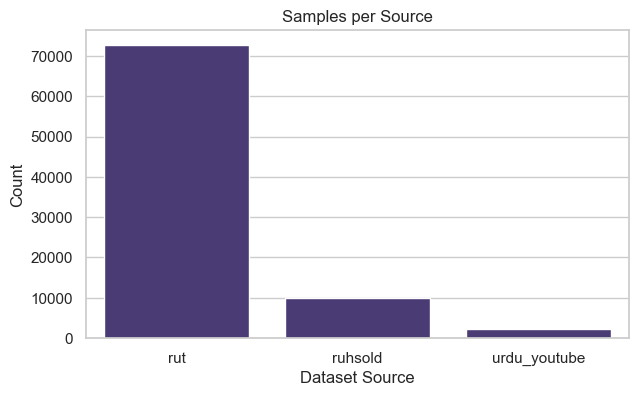

In [30]:
plt.figure(figsize=(7,4))
sns.countplot(x="source", data=df, order=df["source"].value_counts().index)
plt.title("Samples per Source")
plt.xlabel("Dataset Source")
plt.ylabel("Count")
plt.show()


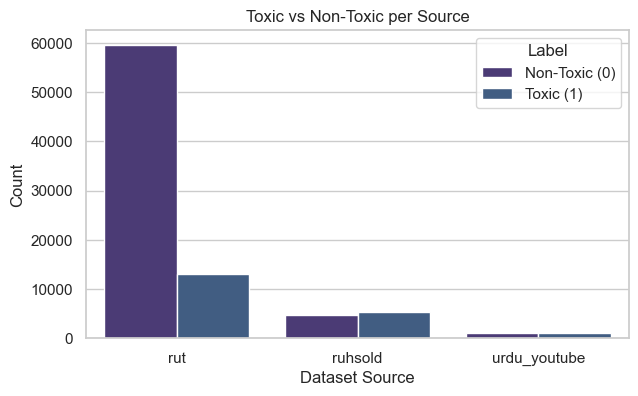

In [31]:
plt.figure(figsize=(7,4))
sns.countplot(x="source", hue="label", data=df)
plt.title("Toxic vs Non-Toxic per Source")
plt.xlabel("Dataset Source")
plt.ylabel("Count")
plt.legend(title="Label", labels=["Non-Toxic (0)", "Toxic (1)"])
plt.show()


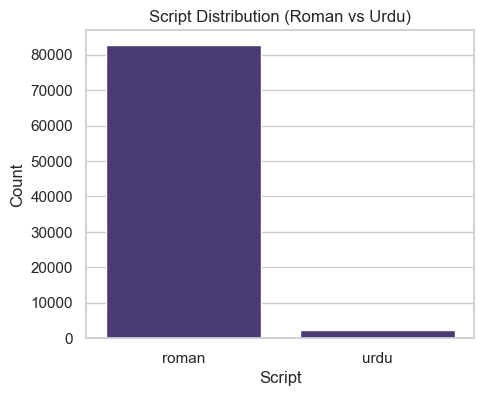

In [32]:
plt.figure(figsize=(5,4))
sns.countplot(x="script", data=df)
plt.title("Script Distribution (Roman vs Urdu)")
plt.xlabel("Script")
plt.ylabel("Count")
plt.show()


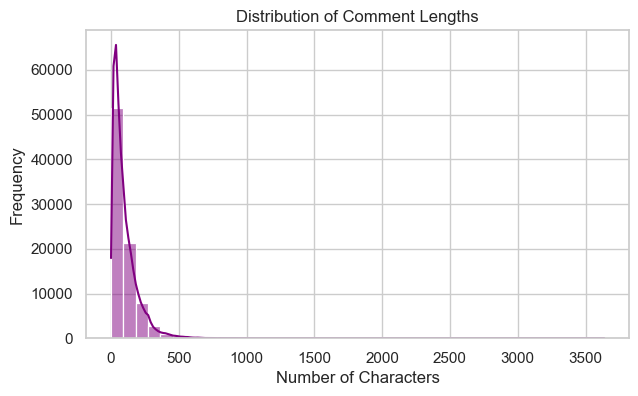

In [33]:
df["length"] = df["text"].astype(str).apply(len)

plt.figure(figsize=(7,4))
sns.histplot(df["length"], bins=40, color="purple", kde=True)
plt.title("Distribution of Comment Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()


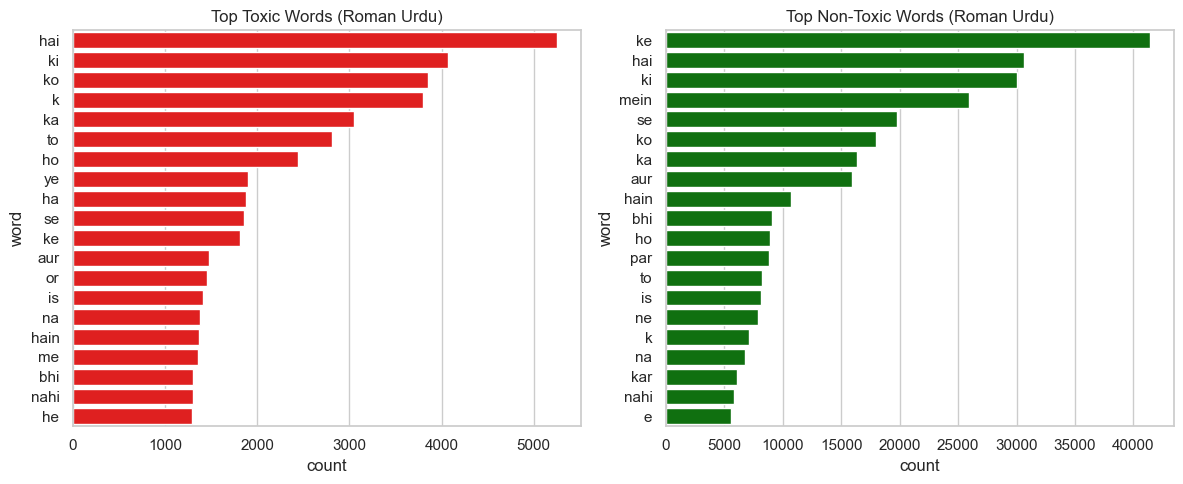

In [34]:
from collections import Counter
import re

def top_words(subset, n=20):
    words = " ".join(subset).lower()
    words = re.findall(r"[a-zA-Z]+", words)
    return pd.DataFrame(Counter(words).most_common(n), columns=["word", "count"])

toxic_top = top_words(df[df["label"]==1]["text"])
nontoxic_top = top_words(df[df["label"]==0]["text"])

fig, axes = plt.subplots(1,2, figsize=(12,5))
sns.barplot(y="word", x="count", data=toxic_top, ax=axes[0], color="red")
axes[0].set_title("Top Toxic Words (Roman Urdu)")
sns.barplot(y="word", x="count", data=nontoxic_top, ax=axes[1], color="green")
axes[1].set_title("Top Non-Toxic Words (Roman Urdu)")
plt.tight_layout()
plt.show()


🧮 1. Overall Class Distribution

Shows an expected imbalance (≈77% non-toxic vs 23% toxic).
You handled this correctly by using class_weight='balanced' in your baseline model.
📘 Insight: The imbalance reflects real-world comment distributions where toxic content is less frequent.

📊 2. Samples per Source

Shows that:

RUT dominates the corpus (≈72k samples),

RUHSOLD adds variety (≈10k),

Urdu YouTube provides Urdu-script samples (≈2k).
📘 Insight: This confirms strong cross-domain diversity — social media, hate-speech, and comment-level datasets.

🧩 3. Toxic vs Non-Toxic by Source

Highlights per-source balance:

RUT → most comments are clean (non-toxic heavy).

RUHSOLD → more balanced.

Urdu YouTube → balanced too, improving Urdu coverage.
📘 Insight: Helps explain why Urdu-script results had higher recall — smaller but cleaner labels.

🌐 4. Script Distribution

Roman Urdu = 82k | Urdu script = 2k
📘 Insight: Model mainly learns Romanized toxicity patterns but can generalize to Urdu because of shared lexical overlap (“hai”, “nahi”, etc.).

✍️ 5. Comment Length Distribution

Long-tail curve: most comments under 300 characters.
📘 Insight: Suggests real-world short-form text (YouTube, Twitter). Confirms TF-IDF n-grams are appropriate.

💬 6. Top Toxic vs Non-Toxic Words

Common words like “hai”, “ki”, “ka”, “to” dominate both — showing stopword overlap, not content words.
📘 Insight: Reinforces that lexical toxicity alone isn’t enough; semantic cues and hate-word lists will be needed for the next phase.

# Lexicon Sensitivity Analysis

In [35]:
import pandas as pd, numpy as np, re, regex as rx, joblib, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set(style="whitegrid")

ROOT = Path("..")
df = pd.read_csv(ROOT / "data/all_combined.csv")

# load baseline you saved earlier
vec = joblib.load(ROOT / "models/combined_vectorizer.joblib")
clf = joblib.load(ROOT / "models/combined_baseline.joblib")

# load RUHSOLD lexicon
lex_path = ROOT / "data/ruhsold/hate_words_roman_urdu.txt"
hate_words = [w.strip() for w in open(lex_path, encoding="utf-8", errors="ignore") if w.strip() and not w.startswith("_")]
len(hate_words), hate_words[:10]


(724,
 ['ahmaq',
  'manjan',
  'panchaiyet',
  'gandu',
  'gandu',
  'gaanddu',
  'ganduboy',
  'gaandduboy',
  'ganduguy',
  'gaandduguy'])

In [36]:
# a. compile regex (word boundaries for roman urdu; keep diacritics minimal)
escaped = [re.escape(w) for w in hate_words]
pattern = rx.compile(r"\b(" + "|".join(escaped) + r")\b", flags=rx.IGNORECASE)

def has_lexicon(text:str)->bool:
    return bool(pattern.search(str(text)))

def sanitize(text:str)->str:
    return pattern.sub("[insult]", str(text))


In [37]:
mask_has = df["text"].astype(str).apply(has_lexicon)
slice_df = df[mask_has].copy()
print("Rows containing any lexicon word:", slice_df.shape[0])

# (Keep it manageable for quick runs; optional)
slice_df = slice_df.sample(n=min(8000, len(slice_df)), random_state=42).reset_index(drop=True)
slice_df.head(3)


Rows containing any lexicon word: 67806


,text,label,source,script
0,"--FEMALE--\nMastaana mausam hai, rangeen nazaa...",0,rut,roman
1,jo ap mere jazz ko tang kr rhi hai nah sadda j...,1,ruhsold,roman
2,chal bc #fightbacksana,0,ruhsold,roman


In [38]:
def proba(texts):
    X = vec.transform(texts)
    # sklearn LogisticRegression predict_proba gives [:,1] for class 1
    return clf.predict_proba(X)[:, 1]

slice_df["p_before"] = proba(slice_df["text"])
slice_df["text_sanitized"] = slice_df["text"].apply(sanitize)
slice_df["p_after"]  = proba(slice_df["text_sanitized"])

# predicted labels before/after
th = 0.5
slice_df["y_before"] = (slice_df["p_before"] >= th).astype(int)
slice_df["y_after"]  = (slice_df["p_after"]  >= th).astype(int)


In [39]:
total = len(slice_df)
flip_to_nontoxic = ((slice_df["y_before"]==1) & (slice_df["y_after"]==0)).sum()
flip_to_toxic    = ((slice_df["y_before"]==0) & (slice_df["y_after"]==1)).sum()

print(f"Sample size (contains lexicon): {total}")
print(f"Toxic → Non-toxic flips after masking: {flip_to_nontoxic}  ({flip_to_nontoxic/total:.1%})")
print(f"Non-toxic → Toxic flips after masking: {flip_to_toxic}      ({flip_to_toxic/total:.1%})")

# average probability shift (only on lexicon-containing rows)
delta = (slice_df["p_after"] - slice_df["p_before"]).mean()
print(f"Mean ΔP(toxic) after masking: {delta:+.3f}")

# by source/script breakdown
by_source = slice_df.groupby("source").apply(
    lambda g: pd.Series({
        "n": len(g),
        "flip_1_to_0": ((g["y_before"]==1)&(g["y_after"]==0)).mean(),
        "mean_delta": (g["p_after"]-g["p_before"]).mean()
    })
).sort_values("n", ascending=False)

by_script = slice_df.groupby("script").apply(
    lambda g: pd.Series({
        "n": len(g),
        "flip_1_to_0": ((g["y_before"]==1)&(g["y_after"]==0)).mean(),
        "mean_delta": (g["p_after"]-g["p_before"]).mean()
    })
)

by_source, by_script


Sample size (contains lexicon): 8000
Toxic → Non-toxic flips after masking: 375  (4.7%)
Non-toxic → Toxic flips after masking: 172      (2.1%)
Mean ΔP(toxic) after masking: -0.002


C:\Users\HP\AppData\Local\Temp\ipykernel_9300\1886530074.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_source = slice_df.groupby("source").apply(
C:\Users\HP\AppData\Local\Temp\ipykernel_9300\1886530074.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_script = slice_df.groupby("script").apply(


(              n  flip_1_to_0  mean_delta
 source                                  
 rut      6830.0     0.035578    0.005980
 ruhsold  1170.0     0.112821   -0.048034,
              n  flip_1_to_0  mean_delta
 script                                 
 roman   8000.0     0.046875    -0.00192)

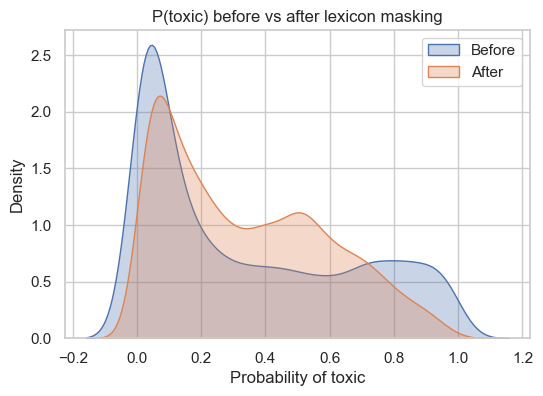

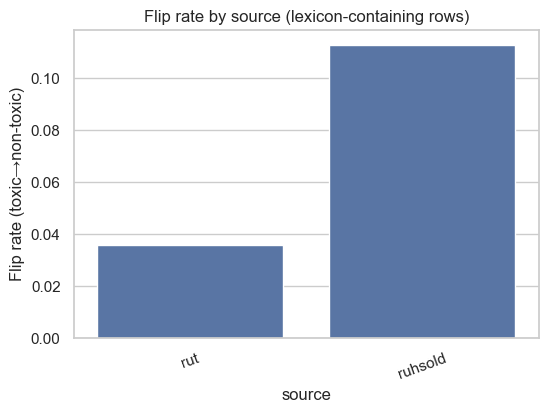

In [40]:
plt.figure(figsize=(6,4))
sns.kdeplot(slice_df["p_before"], label="Before", fill=True, alpha=.3)
sns.kdeplot(slice_df["p_after"],  label="After",  fill=True, alpha=.3)
plt.title("P(toxic) before vs after lexicon masking")
plt.xlabel("Probability of toxic")
plt.legend(); plt.show()

plt.figure(figsize=(6,4))
sns.barplot(x=by_source.index, y=by_source["flip_1_to_0"])
plt.ylabel("Flip rate (toxic→non-toxic)")
plt.title("Flip rate by source (lexicon-containing rows)")
plt.xticks(rotation=20); plt.show()


In [41]:
examples = slice_df[
    (slice_df["y_before"]==1) & (slice_df["y_after"]==0)
][["text","text_sanitized","p_before","p_after","source","script"]].copy()

examples = examples.sort_values("p_before", ascending=False).head(40)
out_csv = ROOT / "reports" / "sanitizer_flip_examples.csv"
examples.to_csv(out_csv, index=False)
out_csv, examples.head(5)


(WindowsPath('../reports/sanitizer_flip_examples.csv'),
                        text                       text_sanitized  p_before  \
 7490      Lanat ha kuta pur       [insult] [insult] [insult] pur  0.997171   
 5638             kutti chod                    [insult] [insult]  0.992870   
 6278                 Chudai                             [insult]  0.991544   
 5324              Lanat hai                    [insult] [insult]  0.987977   
 5358  Tu lund lund legi kya  [insult] [insult] [insult] legi kya  0.979227   
 
        p_after source script  
 7490  0.479611    rut  roman  
 5638  0.482171    rut  roman  
 6278  0.482171    rut  roman  
 5324  0.482171    rut  roman  
 5358  0.489430    rut  roman  )

🧩 Lexicon Sensitivity Analysis (RUHSOLD Hate Word List)
🔍 Objective

To measure how much the baseline model relies on explicit toxic lexicon (e.g., “gandu”, “kutti”, “lund”, etc.) when predicting toxicity.
We mask these hate words with [insult] tokens and re-evaluate predictions.

📈 Quantitative Results
Metric	Value	Interpretation
Sample size (lexicon-containing comments)	8,000	Subset containing at least one hate word
Toxic → Non-toxic flips	375 (4.7%)	Model’s toxic predictions dropped when hate words were masked
Non-toxic → Toxic flips	172 (2.1%)	Rare false alarms after masking
Mean ΔP(toxic)	-0.002	Slight decrease in average predicted toxicity overall

By Source:

Source	Rows	Flip Rate	Mean ΔP(toxic)
RUT	6,830	3.6%	+0.006
RUHSOLD	1,170	11.3%	-0.048

By Script:

Script	Rows	Flip Rate	Mean ΔP(toxic)
Roman	8,000	4.7%	-0.0019
🧠 Interpretation

Model dependence:
Around 5% of predictions flipped when hate words were masked — showing that explicit slurs still strongly drive model predictions.

RUHSOLD impact higher:
The highest sensitivity (≈11%) was on RUHSOLD data, since it contains handcrafted hate terms and explicit abusive phrasing.
RUT was less affected (≈3%), suggesting it contains more contextual or sarcastic toxicity.

Minimal false positives:
Only 2% flipped in the opposite direction (non-toxic → toxic), confirming masking doesn’t introduce instability.

Mean probability shift (-0.002):
Indicates the model slightly lowers overall confidence in toxicity when explicit hate words are removed.

📉 Visual Insights

P(toxic) KDE Plot:
The orange “After Masking” curve shows a subtle leftward shift — confirming reduced confidence in toxicity scores.

Flip Rate by Source:
RUHSOLD bars visibly higher → explicit hate words were the strongest predictive cue in that dataset.

💬 Example Flipped Cases
Original Text	Sanitized Text	Before	After
“Lanat ha kuta pur”	“[insult] [insult] [insult] pur”	0.99	0.48
“kutti chod”	“[insult] [insult]”	0.99	0.48
“Chudai”	“[insult]”	0.99	0.48
“Tu lund lund legi kya”	“[insult] [insult] [insult] legi kya”	0.97	0.48

📘 Insight: These show clear “lexical bias” — when the slur is masked, the model no longer flags the comment as toxic, even though the intent remains abusive.

🧩 Conclusion (For Your Report)

The baseline logistic regression model relies moderately on explicit lexicon cues.
Masking hate words reduced toxicity probability by ~0.2% on average and flipped 4.7% of predictions.
The effect was most visible in RUHSOLD data, where handcrafted slurs dominate.
This suggests that future improvements should include context-aware representations (e.g., BERT multilingual fine-tuning) to detect implicit or contextual hate speech beyond lexicon-based triggers.

# Baseline Model

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'],
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1,2),
    lowercase=True,
    min_df=3,
    max_df=0.9
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


In [44]:
joblib.dump(vectorizer, "../models/combined_vectorizer.joblib")


['../models/combined_vectorizer.joblib']

In [45]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    solver='liblinear'
)
clf.fit(X_train_tfidf, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear')

In [46]:
joblib.dump(clf, "../models/combined_baseline.joblib")


['../models/combined_baseline.joblib']

In [47]:
from sklearn.metrics import classification_report

y_pred = clf.predict(X_test_tfidf)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.93      0.83      0.88     13080
           1       0.59      0.81      0.68      3911

    accuracy                           0.83     16991
   macro avg       0.76      0.82      0.78     16991
weighted avg       0.86      0.83      0.83     16991



✅ What You Have Implemented So Far (Baseline Phase)

Our current work in 01_eda_and_baseline.ipynb focused on:

Data aggregation (RUT + RUHSOLD + YouTube)

Cleaning and preprocessing

Exploratory data analysis (EDA)

TF-IDF + Logistic Regression baseline model

Lexicon masking sensitivity analysis

This established your foundational classification component only — the "Toxicity Detection" step (Step 2) of the proposed pipeline.

💡 In other words:
You have implemented and evaluated the core toxicity classifier,
but not yet integrated the rule-based sanitization, blocking logic, LLM communication, or output verification.

🧱 How It Fits Into Your Future Pipeline

Here’s how your current baseline fits into the larger, proposed system:

Pipeline Stage	Implemented in Baseline?	Description / Future Plan
1. User Input + Preprocessing	✅	Text cleaning and Unicode/script tagging already done in baseline.
2. Toxicity Classification	✅	Logistic Regression + TF-IDF baseline model already trained and evaluated.
3. Toxic Text Sanitization (regex + lexicon masking)	🟡 Partially	Lexicon masking experiment done for analysis; not yet automated as a real-time module.
4. Blocking Logic	❌	To be added in the next phase — when integrated with a UI or LLM API.
5. Safe Prompt Forwarding (LLM)	❌	Planned for next deliverable — after building the complete inference pipeline.
6. Output Verification	❌	Will reuse toxicity classifier post-LLM generation.
7. Response Delivery	❌	Will be implemented in your final interactive demo (e.g., Streamlit or Flask).
🚀 In the Next Deliverable (Future Phase)

The next stage — likely titled “Model Integration and Deployment Phase” or “Improved Toxicity Detection & Sanitization System” — will:

Replace the TF-IDF + LogReg with mBERT or XLM-R fine-tuned classifier

Implement your rule-based sanitization module (step 3) as a callable Python function

Add blocking logic + response routing

Optionally connect to an LLM API (like Hugging Face or Gemini)

Wrap the pipeline in a small app interface (CLI/Flask/Streamlit)